# Lezione 13 — Caso TakeHome  
## First Republic Bank 2023: due ondate di deposit run e vincoli di ristrutturazione del bilancio

**Esito del Prompt 1 — Inquadramento del caso**

Questo notebook sviluppa il Caso TakeHome della Lezione 13 come problema autonomo di programmazione lineare e Asset--Liability Management deterministico.

La banca sceglie l'allocazione iniziale tra cinque classi di attivo, gestisce quattro giacenze di liquidità e può ricorrere a funding esterno nelle prime tre date. Il modello include:

- una prima ondata di fabbisogno parametrizzata da $\alpha$ alla data 1;
- una seconda ondata parametrizzata da $\beta$ alla data 4;
- una capacità massima di funding parametrizzata da $\phi$;
- un vincolo legacy $x_3+x_4\geq 35$;
- un limite separato $x_5\leq 35$.

La domanda quantitativa è: **come cambia il piano ALM ottimo al variare separatamente dell'intensità della prima ondata, della seconda ondata e della capacità disponibile di funding, e come cambiano i risultati negli scenari congiunti assegnati?**

### Quantità da determinare

- soluzione benchmark $x^*$, $g^*$, $u^*$ e valore ottimo $\Pi^*$;
- residuali, slack, bounds attivi e principali marginali;
- sensitività univariate rispetto ad $\alpha$, $\beta$ e $\phi$;
- variazioni rispetto al benchmark;
- utilizzo della capacità di funding;
- confronto tra shock alla prima e alla quarta data;
- comportamento e marginale del vincolo legacy;
- risultati degli scenari Standard, Mediamente critico e Critico.

### Output richiesti

**Tabelle**

1. Benchmark e diagnostica.
2. Sensitività ad $\alpha$.
3. Sensitività a $\beta$.
4. Sensitività a $\phi$.
5. Confronto degli scenari.
6. Controllo del vincolo legacy.

**Figure**

1. $\Pi^*(\alpha)$.
2. $\Pi^*(\beta)$.
3. $\Pi^*(\phi)$ e comportamento del funding.
4. Composizione ottima dell'attivo lungo una sensitività informativa.
5. Utilizzo della capacità di funding lungo $\phi$.
6. Confronto diretto tra prima e seconda ondata.

### Controlli

Devono essere verificati stato del solver, bilanci temporali, vincolo prudenziale, vincolo legacy, limite su $x_5$, bounds del funding, non negatività, coerenza fra slack e vincoli attivi, corretto ruolo dei tre driver e corretta interpretazione locale dei marginali.

La **Scheda Caso è la specifica vincolante**: variabili, formule, parametri, griglie, scenari, output e controlli non vengono modificati.

# Flusso logico-teorico risolutivo

**Esito del Prompt 2 — Regime A**

| Passo | Finalità risolutiva | Oggetto teorico | Applicazione nel caso | Output o controllo |
|---:|---|---|---|---|
| 1 | Ricostruire il nuovo problema | Struttura PL/ALM | 5 attivi, 4 giacenze, 3 funding, due ondate, legacy, limite $x_5$ | Mappa del caso |
| 2 | Tradurre nella forma solver | $\max\Pi \leftrightarrow \min(-\Pi)$; $A_{eq},b_{eq},A_{ub},b_{ub}$ | Forma matriciale completa | Controlli dimensionali e segni |
| 3 | Risolvere il benchmark | Ammissibilità, ottimalità, residuali, slack | $(1,1,1)$ | $x^*,g^*,u^*,\Pi^*$ e diagnostica |
| 4 | Verificare il legacy | Vincolo inferiore e forma $\leq$ | $x_3+x_4\geq L \Rightarrow -x_3-x_4\leq-L$ | Codifica e marginale |
| 5 | Derivare il marginale legacy | $F=-\Pi$, $b=-L$ | $\partial\Pi^*/\partial L=m$ | Controllo perturbativo |
| 6 | Costruire il solver parametrico | Parametrizzazione di RHS e bounds | $\alpha,\beta,\phi$ | Riproduzione benchmark |
| 7 | Sensitività prima ondata | Comparative statics | varia solo $\alpha$ | Tabella/figure $\alpha$ |
| 8 | Sensitività seconda ondata | Comparative statics | varia solo $\beta$ | Tabella/figure $\beta$ |
| 9 | Confrontare le due ondate | Struttura temporale ALM | shock relativi omogenei | Confronto $\alpha$--$\beta$ |
| 10 | Sensitività funding | Bounds parametrizzati | varia solo $\phi$ | Tabella/figure $\phi$ |
| 11 | Confrontare i driver | Comparative statics | lettura congiunta ma non scenario | Sintesi |
| 12 | Scenario analysis | Scenari deterministici | variazione congiunta assegnata | Tabella scenari |
| 13 | Controlli conclusivi | Coerenza modello--solver--output | riproducibilità e limiti | Validazione finale |

# Scomposizione operativa in tappe input-output

**Esito del Prompt 3 — Regime A/B**

| Tappa | Titolo | Obiettivo | Input | Operazione | Output | Controllo | Regime |
|---:|---|---|---|---|---|---|:---:|
| 1 | Ricognizione | Distinguere il TakeHome dall'Aula | Scheda Caso | Identificare elementi strutturali | Mappa operativa | Autonomia dal caso Aula | A |
| 2 | Forma solver | Tradurre il modello | Parametri e formule | Costruire vettori, matrici e bounds | Struttura solver | Dimensioni e segni | A/B |
| 3 | Benchmark | Risolvere e validare $(1,1,1)$ | Forma solver | `linprog` + diagnostica | Soluzione benchmark | Fattibilità e vincoli | B |
| 4 | Legacy | Validare vincolo e marginale | Benchmark | Perturbare $L$ | Tabella legacy | $\partial\Pi^*/\partial L=m$ | A/B |
| 5 | Solver parametrico | Generalizzare il benchmark | Modello validato | Definire `solve_model` | Funzione riutilizzabile | Riproduzione benchmark | A/B |
| 6 | Sensitività $\alpha$ | Prima ondata | Griglia $\alpha$ | Risolvere griglia | Tabella e figure | Varia solo $\alpha$ | B |
| 7 | Sensitività $\beta$ | Seconda ondata | Griglia $\beta$ | Risolvere griglia | Tabella e figure | Varia solo $\beta$ | B |
| 8 | Confronto ondate | Misurare effetto del timing | Risultati $\alpha,\beta$ | Confronto omogeneo | Figura e sintesi | Nessuna variazione simultanea | A |
| 9 | Sensitività $\phi$ | Capacità di funding | Griglia $\phi$ | Risolvere griglia | Tabella e figure | Varia solo bounds funding | B |
| 10 | Confronto sensitività | Leggere i tre driver | Tappe 6--9 | Sintesi quantitativa | Tabella di confronto | Distinzione da scenari | A |
| 11 | Scenari | Variazioni congiunte | Tre scenari assegnati | Risolvere scenari | Tabella scenari | Parametri esatti e validità | B |
| 12 | Controlli conclusivi | Validare il notebook | Tutti gli output | Checklist finale | Esito validazione | Riproducibilità | A |

## Tappa 1 — Ricognizione del nuovo problema  
**Regime A**

**Obiettivo.** Rendere espliciti gli elementi che impediscono di trattare il TakeHome come semplice sostituzione di coefficienti del Caso Aula.

**Elementi distintivi.**

- cinque classi di attivo, non quattro;
- due driver temporali distinti: $\alpha$ agisce solo sulla data 1, $\beta$ solo sulla data 4;
- $\phi$ agisce solo sulla capacità massima di funding;
- il costo del funding resta invariato;
- presenza del vincolo inferiore legacy $x_3+x_4\geq35$;
- presenza del limite separato $x_5\leq35$;
- nessun parametro analogo a $\psi$ del Caso Aula.

**Controllo.** La forma solver verrà costruita ex novo a partire dalla specifica First Republic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

TOL = 1e-8
print("Librerie caricate. Tolleranza numerica:", TOL)

Matplotlib is building the font cache; this may take a moment.


Librerie caricate. Tolleranza numerica: 1e-08


## Tappa 2 — Traduzione del modello nella forma solver  
**Regime A/B**

**Ordinamento vincolante delle variabili**

$$
z=(x_1,x_2,x_3,x_4,x_5,g_1,g_2,g_3,g_4,u_1,u_2,u_3)'.
$$

Il solver minimizza $F=-\Pi$. I quattro bilanci temporali, insieme al vincolo sulle risorse iniziali, entrano in $A_{\mathrm{eq}}z=b_{\mathrm{eq}}$.

Le disuguaglianze sono:

$$
\ell'x\leq7.5,
\qquad
-x_3-x_4\leq-35,
\qquad
x_5\leq35.
$$

I limiti $0\leq u_t\leq\bar u_t$ sono implementati come bounds.

In [2]:
# Parametri benchmark
A0 = 100.0
c = np.array([0.008, 0.022, 0.035, 0.045, 0.050])
ell = np.array([0.000, 0.015, 0.060, 0.100, 0.120])

A_CF = np.array([
    [1.00, 0.70, 0.05, 0.05, 0.10],
    [0.00, 0.30, 0.10, 0.15, 0.20],
    [0.00, 0.00, 0.25, 0.30, 0.30],
    [0.00, 0.00, 0.60, 0.50, 0.40],
])

d_bench = np.array([32.0, 18.0, 14.0, 32.0])
r_g = np.array([0.004, 0.005, 0.006])
r_u = np.array([0.018, 0.025, 0.040])
u_bar = np.array([4.0, 3.0, 2.0])
K = 7.5
L_legacy = 35.0
x5_max = 35.0

names = [f"x{i}" for i in range(1, 6)] + [f"g{i}" for i in range(1, 5)] + [f"u{i}" for i in range(1, 4)]
idx = {name: i for i, name in enumerate(names)}
n_var = len(names)

parametri = pd.DataFrame({
    "quantita": ["A0", "K", "L_legacy", "x5_max"],
    "valore": [A0, K, L_legacy, x5_max]
})
display(parametri)
print("Numero variabili:", n_var)
print("Ordine:", names)

,quantita,valore
0,A0,100.0
1,K,7.5
2,L_legacy,35.0
3,x5_max,35.0


Numero variabili: 12
Ordine: ['x1', 'x2', 'x3', 'x4', 'x5', 'g1', 'g2', 'g3', 'g4', 'u1', 'u2', 'u3']


### Costruzione benchmark della forma solver

Per il benchmark si usa $d=(32,18,14,32)'$ e $\phi=1$.

Il vettore da minimizzare è:

$$
f=(-c_1,\ldots,-c_5,-r_1^g,-r_2^g,-r_3^g,0,r_1^u,r_2^u,r_3^u)'.
$$

La costruzione seguente mantiene separati uguaglianze, disuguaglianze e bounds, così da rendere verificabile la corrispondenza con il modello economico.

In [3]:
# Vettore obiettivo per min F = -Pi
f = np.zeros(n_var)
f[:5] = -c
f[idx["g1"]:idx["g4"]] = -r_g
f[idx["u1"]:idx["u3"] + 1] = r_u

# Uguaglianze: risorse iniziali + 4 bilanci temporali
A_eq = []
b_eq = []

row = np.zeros(n_var)
row[:5] = 1.0
A_eq.append(row)
b_eq.append(A0)

# t=1
row = np.zeros(n_var)
row[:5] = A_CF[0]
row[idx["u1"]] = 1.0
row[idx["g1"]] = -1.0
A_eq.append(row)
b_eq.append(d_bench[0])

# t=2
row = np.zeros(n_var)
row[:5] = A_CF[1]
row[idx["g1"]] = 1.0 + r_g[0]
row[idx["u1"]] = -(1.0 + r_u[0])
row[idx["u2"]] = 1.0
row[idx["g2"]] = -1.0
A_eq.append(row)
b_eq.append(d_bench[1])

# t=3
row = np.zeros(n_var)
row[:5] = A_CF[2]
row[idx["g2"]] = 1.0 + r_g[1]
row[idx["u2"]] = -(1.0 + r_u[1])
row[idx["u3"]] = 1.0
row[idx["g3"]] = -1.0
A_eq.append(row)
b_eq.append(d_bench[2])

# t=4
row = np.zeros(n_var)
row[:5] = A_CF[3]
row[idx["g3"]] = 1.0 + r_g[2]
row[idx["u3"]] = -(1.0 + r_u[2])
row[idx["g4"]] = -1.0
A_eq.append(row)
b_eq.append(d_bench[3])

A_eq = np.array(A_eq)
b_eq = np.array(b_eq)

# Disuguaglianze
A_ub = []
b_ub = []

row = np.zeros(n_var)
row[:5] = ell
A_ub.append(row)
b_ub.append(K)

row = np.zeros(n_var)
row[idx["x3"]] = -1.0
row[idx["x4"]] = -1.0
A_ub.append(row)
b_ub.append(-L_legacy)

row = np.zeros(n_var)
row[idx["x5"]] = 1.0
A_ub.append(row)
b_ub.append(x5_max)

A_ub = np.array(A_ub)
b_ub = np.array(b_ub)

bounds = [(0.0, None)] * 9 + [(0.0, u_bar[t]) for t in range(3)]

print("f:", f.shape)
print("A_eq, b_eq:", A_eq.shape, b_eq.shape)
print("A_ub, b_ub:", A_ub.shape, b_ub.shape)
print("bounds:", len(bounds))

f: (12,)
A_eq, b_eq: (5, 12) (5,)
A_ub, b_ub: (3, 12) (3,)
bounds: 12


### Controllo della forma solver

**Controlli richiesti**

- $f$ deve avere 12 componenti;
- $A_{\mathrm{eq}}$ deve avere 5 righe e 12 colonne;
- $A_{\mathrm{ub}}$ deve avere 3 righe e 12 colonne;
- il RHS legacy deve essere $-35$;
- i bounds del funding devono essere $(0,4)$, $(0,3)$, $(0,2)$;
- la trasformazione della funzione obiettivo deve rispettare $\max\Pi\leftrightarrow\min(-\Pi)$.

In [4]:
assert f.shape == (12,)
assert A_eq.shape == (5, 12)
assert b_eq.shape == (5,)
assert A_ub.shape == (3, 12)
assert b_ub.shape == (3,)
assert len(bounds) == 12
assert np.allclose(A_ub[1, [idx["x3"], idx["x4"]]], [-1.0, -1.0])
assert np.isclose(b_ub[1], -35.0)
assert bounds[idx["u1"]] == (0.0, 4.0)
assert bounds[idx["u2"]] == (0.0, 3.0)
assert bounds[idx["u3"]] == (0.0, 2.0)

print("Controlli dimensionali, segni e bounds: OK")

Controlli dimensionali, segni e bounds: OK


## Tappa 3 — Soluzione e validazione del benchmark  
**Regime B**

Si risolve la configurazione:

$$
(\alpha,\beta,\phi)=(1,1,1).
$$

Prima di utilizzare qualsiasi valore della soluzione si verifica `res.success`.

Il valore economico è ricostruito come:

$$
\Pi^*=-F^*.
$$

In [5]:
res_bench = linprog(
    f,
    A_ub=A_ub, b_ub=b_ub,
    A_eq=A_eq, b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("success:", res_bench.success)
print("status :", res_bench.status)
print("message:", res_bench.message)

if not res_bench.success:
    raise RuntimeError("Il benchmark non è risolvibile: interrompere la validazione.")

z_bench = res_bench.x
x_bench = z_bench[:5]
g_bench = z_bench[5:9]
u_bench = z_bench[9:12]
Pi_bench = -res_bench.fun

sol_bench = pd.DataFrame({
    "variabile": names,
    "valore": z_bench
})
display(sol_bench)

print("Pi* =", Pi_bench)

success: True
status : 0
message: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,variabile,valore
0,x1,0.000000
1,x2,36.190476
2,x3,0.000000
3,x4,35.000000
4,x5,28.809524
5,g1,0.000000
6,g2,1.796690
7,g3,6.948531
8,g4,4.014032
9,u1,2.035714


Pi* = 3.8256984483333336


### Diagnostica benchmark

La validazione non si limita a `success=True`.

Si controllano:

- residuali delle 5 uguaglianze;
- slack di prudenziale, legacy e limite su $x_5$;
- bounds attivi;
- non negatività;
- marginali delle uguaglianze e delle disuguaglianze.

Un vincolo è considerato attivo quando lo slack è inferiore alla tolleranza dichiarata.

In [6]:
eq_resid = A_eq @ z_bench - b_eq
ub_slack = b_ub - A_ub @ z_bench

vincoli_ub = ["prudenziale", "legacy", "x5_max"]
diag_ub = pd.DataFrame({
    "vincolo": vincoli_ub,
    "slack": ub_slack,
    "attivo": np.abs(ub_slack) <= TOL,
    "marginale_solver": res_bench.ineqlin.marginals
})

diag_eq = pd.DataFrame({
    "uguaglianza": ["risorse", "bilancio_t1", "bilancio_t2", "bilancio_t3", "bilancio_t4"],
    "residuo": eq_resid,
    "marginale_solver": res_bench.eqlin.marginals
})

active_bounds = []
for j, (lo, hi) in enumerate(bounds):
    value = z_bench[j]
    low_active = lo is not None and abs(value - lo) <= TOL
    up_active = hi is not None and abs(value - hi) <= TOL
    if low_active or up_active:
        active_bounds.append({
            "variabile": names[j],
            "valore": value,
            "lower_attivo": low_active,
            "upper_attivo": up_active
        })
active_bounds = pd.DataFrame(active_bounds)

benchmark_diagnostica = pd.DataFrame({
    "indicatore": [
        "Pi*", "max |residuo eq|", "slack prudenziale",
        "slack legacy", "slack x5_max", "min variabile"
    ],
    "valore": [
        Pi_bench, np.max(np.abs(eq_resid)), ub_slack[0],
        ub_slack[1], ub_slack[2], z_bench.min()
    ]
})

display(benchmark_diagnostica)
display(diag_eq)
display(diag_ub)
display(active_bounds)

assert np.max(np.abs(eq_resid)) <= 1e-7
assert np.all(ub_slack >= -1e-7)
assert z_bench.min() >= -1e-7
print("Validazione numerica benchmark: OK")

,indicatore,valore
0,Pi*,3.825698
1,max |residuo eq|,0.000000
2,slack prudenziale,0.000000
3,slack legacy,0.000000
4,slack x5_max,6.190476
5,min variabile,0.000000


,uguaglianza,residuo,marginale_solver
0,risorse,0.0,-0.044175
1,bilancio_t1,0.0,0.029229
2,bilancio_t2,0.0,0.011030
3,bilancio_t3,0.0,0.006000
4,bilancio_t4,0.0,-0.000000


,vincolo,slack,attivo,marginale_solver
0,prudenziale,0.000000,True,-0.106285
1,legacy,0.000000,True,-0.004887
2,x5_max,6.190476,False,-0.000000


,variabile,valore,lower_attivo,upper_attivo
0,x1,0.0,True,False
1,x3,0.0,True,False
2,g1,0.0,True,False
3,u2,0.0,True,False
4,u3,0.0,True,False


Validazione numerica benchmark: OK


## Tappa 4 — Vincolo legacy e relativo marginale  
**Regime A/B**

La forma economica è:

$$
x_3+x_4\geq L,\qquad L=35.
$$

La forma solver è:

$$
-x_3-x_4\leq b,\qquad b=-L.
$$

Il solver minimizza $F=-\Pi$. Se il marginale della riga legacy è:

$$
m=\frac{\partial F^*}{\partial b},
$$

allora le due inversioni di segno si compensano e:

$$
\frac{\partial\Pi^*}{\partial L}=m.
$$

La relazione è locale e va verificata mediante una piccola perturbazione di $L$.

In [7]:
m_legacy = float(res_bench.ineqlin.marginals[1])
delta_L = 0.01

b_ub_pert = b_ub.copy()
b_ub_pert[1] = -(L_legacy + delta_L)

res_pert = linprog(
    f,
    A_ub=A_ub, b_ub=b_ub_pert,
    A_eq=A_eq, b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

if not res_pert.success:
    raise RuntimeError("La perturbazione legacy non è risolvibile.")

Pi_pert = -res_pert.fun
derivata_numerica = (Pi_pert - Pi_bench) / delta_L

tab_legacy = pd.DataFrame({
    "quantita": [
        "x3* + x4*", "L", "slack economico",
        "marginale solver m", "derivata numerica dPi/dL", "errore assoluto"
    ],
    "valore": [
        x_bench[2] + x_bench[3],
        L_legacy,
        x_bench[2] + x_bench[3] - L_legacy,
        m_legacy,
        derivata_numerica,
        abs(derivata_numerica - m_legacy)
    ]
})

display(tab_legacy)
assert abs(derivata_numerica - m_legacy) < 1e-6
print("Verifica perturbativa del marginale legacy: OK")

,quantita,valore
0,x3* + x4*,3.500000e+01
1,L,3.500000e+01
2,slack economico,0.000000e+00
3,marginale solver m,-4.887236e-03
4,derivata numerica dPi/dL,-4.887236e-03
5,errore assoluto,1.589180e-14


Verifica perturbativa del marginale legacy: OK


### Interpretazione locale del controllo legacy

Nel benchmark il vincolo legacy deve essere letto nella sua forma economica, non nella sola forma codificata.

Il controllo precedente verifica direttamente che la variazione numerica di $\Pi^*$ rispetto a un piccolo aumento di $L$ coincida con il marginale restituito dal solver per la riga codificata. **Non si applica un ulteriore cambio di segno.**

Questa verifica deve precedere le sensitività perché la corretta gestione del legacy è parte della validazione del modello.

In [8]:
legacy_check = pd.DataFrame({
    "forma_economica": ["x3 + x4 >= L"],
    "L": [L_legacy],
    "forma_solver": ["-x3 - x4 <= -L"],
    "m_solver": [m_legacy],
    "dPi_dL_numerica": [derivata_numerica],
    "coerente": [abs(derivata_numerica - m_legacy) < 1e-6]
})
display(legacy_check)

,forma_economica,L,forma_solver,m_solver,dPi_dL_numerica,coerente
0,x3 + x4 >= L,35.0,-x3 - x4 <= -L,-0.004887,-0.004887,True


## Tappa 5 — Costruzione del solver parametrico  
**Regime A/B**

La funzione `solve_model(alpha, beta, phi, L)` deve modificare esclusivamente:

$$
d(\alpha,\beta)=(32\alpha,18,14,32\beta)'
$$

e i bounds:

$$
0\leq u_t\leq \phi\bar u_t.
$$

Il costo del funding resta invariato.

Il primo controllo della funzione parametrica è la riproduzione del benchmark in $(1,1,1)$.

In [9]:
def build_problem(alpha=1.0, beta=1.0, phi=1.0, L=35.0):
    d = np.array([32.0 * alpha, 18.0, 14.0, 32.0 * beta])

    f_loc = np.zeros(n_var)
    f_loc[:5] = -c
    f_loc[idx["g1"]:idx["g4"]] = -r_g
    f_loc[idx["u1"]:idx["u3"] + 1] = r_u

    Aeq, beq = [], []

    row = np.zeros(n_var)
    row[:5] = 1.0
    Aeq.append(row); beq.append(A0)

    row = np.zeros(n_var)
    row[:5] = A_CF[0]
    row[idx["u1"]] = 1.0
    row[idx["g1"]] = -1.0
    Aeq.append(row); beq.append(d[0])

    row = np.zeros(n_var)
    row[:5] = A_CF[1]
    row[idx["g1"]] = 1.0 + r_g[0]
    row[idx["u1"]] = -(1.0 + r_u[0])
    row[idx["u2"]] = 1.0
    row[idx["g2"]] = -1.0
    Aeq.append(row); beq.append(d[1])

    row = np.zeros(n_var)
    row[:5] = A_CF[2]
    row[idx["g2"]] = 1.0 + r_g[1]
    row[idx["u2"]] = -(1.0 + r_u[1])
    row[idx["u3"]] = 1.0
    row[idx["g3"]] = -1.0
    Aeq.append(row); beq.append(d[2])

    row = np.zeros(n_var)
    row[:5] = A_CF[3]
    row[idx["g3"]] = 1.0 + r_g[2]
    row[idx["u3"]] = -(1.0 + r_u[2])
    row[idx["g4"]] = -1.0
    Aeq.append(row); beq.append(d[3])

    Aub, bub = [], []

    row = np.zeros(n_var)
    row[:5] = ell
    Aub.append(row); bub.append(K)

    row = np.zeros(n_var)
    row[idx["x3"]] = -1.0
    row[idx["x4"]] = -1.0
    Aub.append(row); bub.append(-L)

    row = np.zeros(n_var)
    row[idx["x5"]] = 1.0
    Aub.append(row); bub.append(x5_max)

    bounds_loc = [(0.0, None)] * 9 + [(0.0, phi * u_bar[t]) for t in range(3)]

    return (
        f_loc,
        np.array(Aeq), np.array(beq),
        np.array(Aub), np.array(bub),
        bounds_loc, d
    )

def solve_model(alpha=1.0, beta=1.0, phi=1.0, L=35.0):
    f_loc, Aeq, beq, Aub, bub, bounds_loc, d = build_problem(alpha, beta, phi, L)

    res = linprog(
        f_loc,
        A_ub=Aub, b_ub=bub,
        A_eq=Aeq, b_eq=beq,
        bounds=bounds_loc,
        method="highs"
    )

    out = {
        "alpha": alpha, "beta": beta, "phi": phi, "L": L,
        "success": bool(res.success), "status": int(res.status), "message": res.message
    }

    if not res.success:
        return out

    z = res.x
    x, g, u = z[:5], z[5:9], z[9:12]
    eq_res = Aeq @ z - beq
    ub_sl = bub - Aub @ z

    out.update({
        "Pi": -res.fun,
        "z": z, "x": x, "g": g, "u": u,
        "eq_residuals": eq_res,
        "ub_slacks": ub_sl,
        "eq_marginals": res.eqlin.marginals,
        "ub_marginals": res.ineqlin.marginals,
        "bounds": bounds_loc
    })
    return out

bench_fun = solve_model(1.0, 1.0, 1.0)
assert bench_fun["success"]
assert np.allclose(bench_fun["z"], z_bench, atol=1e-8)
assert np.isclose(bench_fun["Pi"], Pi_bench, atol=1e-10)

print("La funzione parametrica riproduce il benchmark: OK")

La funzione parametrica riproduce il benchmark: OK


## Tappa 6 — Sensitività rispetto ad $\alpha$  
**Regime B**

Si varia soltanto:

$$
\alpha\in\{0.90,0.95,1.00,1.05,1.10,1.15\},
$$

mantenendo $\beta=\phi=1$.

Per ogni configurazione si registra prima lo stato del solver; quantità ottime e grafici sono prodotti soltanto per configurazioni ammissibili.

,alpha,success,status,Pi,Delta_Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_slack,prud_slack,x5_slack
0,0.90,True,0,3.902750,0.077052,0.0,36.190476,0.0,35.0,28.809524,1.164286,5.03799,10.206038,7.291083,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
1,0.95,True,0,3.872464,0.046766,0.0,36.190476,0.0,35.0,28.809524,0.000000,3.42549,8.585475,5.660797,0.435714,0.108929,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
2,1.00,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.000000,1.79669,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
3,1.05,True,0,3.778933,-0.046766,0.0,36.190476,0.0,35.0,28.809524,0.000000,0.16789,5.311587,2.367266,3.635714,0.908929,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
4,1.10,True,0,3.709183,-0.116515,0.0,38.250000,0.0,35.0,26.750000,0.000000,0.00300,4.528015,0.755183,4.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.21625,8.250000
5,1.15,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


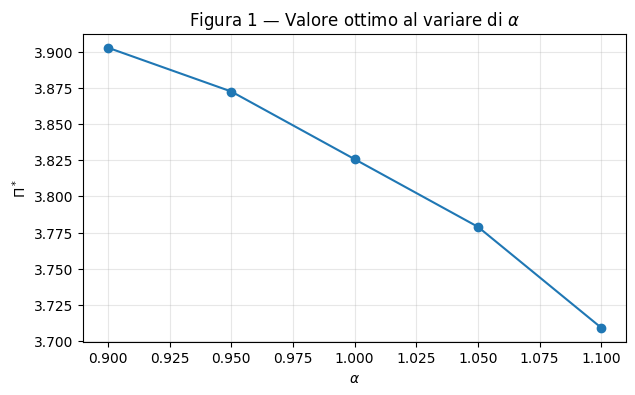

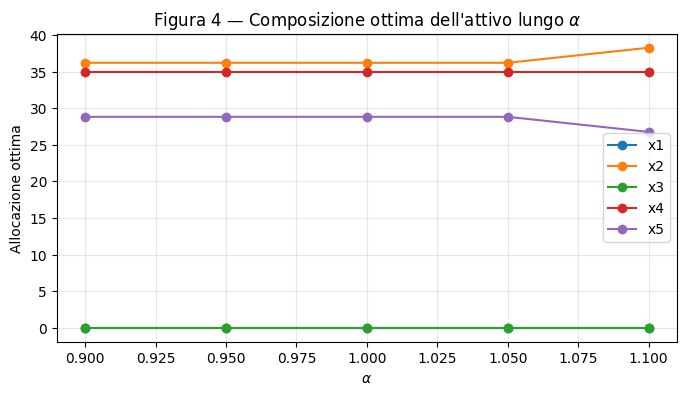

In [10]:
alpha_grid = np.array([0.90, 0.95, 1.00, 1.05, 1.10, 1.15])

def sensitivity_dataframe(param, grid):
    rows = []
    for value in grid:
        kwargs = {"alpha": 1.0, "beta": 1.0, "phi": 1.0}
        kwargs[param] = float(value)
        out = solve_model(**kwargs)

        row = {
            param: value,
            "success": out["success"],
            "status": out["status"]
        }

        if out["success"]:
            row["Pi"] = out["Pi"]
            row["Delta_Pi"] = out["Pi"] - Pi_bench
            for j in range(5):
                row[f"x{j+1}"] = out["x"][j]
            for t in range(4):
                row[f"g{t+1}"] = out["g"][t]
            for t in range(3):
                row[f"u{t+1}"] = out["u"][t]
                denom = (kwargs["phi"] * u_bar[t])
                row[f"rho_u{t+1}"] = out["u"][t] / denom if denom > 0 else np.nan
            row["legacy_slack"] = out["x"][2] + out["x"][3] - L_legacy
            row["prud_slack"] = out["ub_slacks"][0]
            row["x5_slack"] = out["ub_slacks"][2]
        rows.append(row)
    return pd.DataFrame(rows)

df_alpha = sensitivity_dataframe("alpha", alpha_grid)
display(df_alpha)

valid_alpha = df_alpha[df_alpha["success"]].copy()

plt.figure(figsize=(7, 4))
plt.plot(valid_alpha["alpha"], valid_alpha["Pi"], marker="o")
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 1 — Valore ottimo al variare di $\alpha$")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
for col in [f"x{i}" for i in range(1, 6)]:
    plt.plot(valid_alpha["alpha"], valid_alpha[col], marker="o", label=col)
plt.xlabel(r"$\alpha$")
plt.ylabel("Allocazione ottima")
plt.title(r"Figura 4 — Composizione ottima dell'attivo lungo $\alpha$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Tappa 7 — Sensitività rispetto a $\beta$  
**Regime B**

Si varia soltanto:

$$
\beta\in\{0.90,0.95,1.00,1.05,1.10,1.15\},
$$

mantenendo $\alpha=\phi=1$.

La struttura della tabella resta confrontabile con quella di $\alpha$, ma il driver agisce esclusivamente sul fabbisogno terminale.

,beta,success,status,Pi,Delta_Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_slack,prud_slack,x5_slack
0,0.90,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,7.214032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.0,6.190476
1,0.95,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,5.614032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.0,6.190476
2,1.00,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.0,6.190476
3,1.05,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,2.414032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.0,6.190476
4,1.10,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,0.814032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.0,6.190476
5,1.15,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


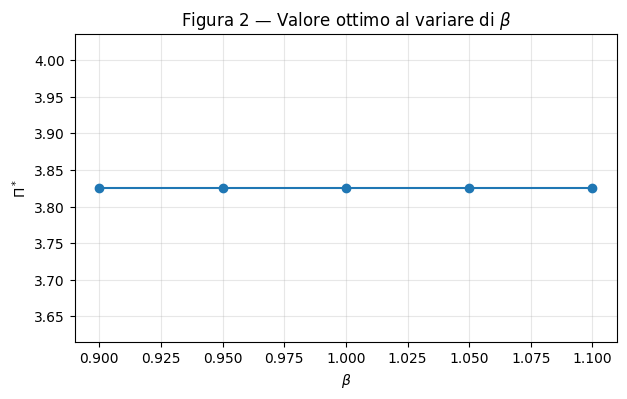

In [11]:
beta_grid = np.array([0.90, 0.95, 1.00, 1.05, 1.10, 1.15])

df_beta = sensitivity_dataframe("beta", beta_grid)
display(df_beta)

valid_beta = df_beta[df_beta["success"]].copy()

plt.figure(figsize=(7, 4))
plt.plot(valid_beta["beta"], valid_beta["Pi"], marker="o")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 2 — Valore ottimo al variare di $\beta$")
plt.grid(True, alpha=0.3)
plt.show()

## Tappa 8 — Confronto tra prima e seconda ondata  
**Regime A**

Le due sensitività sono state costruite separatamente. Il confronto usa valori omogenei del moltiplicatore e non fa variare simultaneamente $\alpha$ e $\beta$.

Si confrontano almeno:

- $\Pi^*$;
- composizione dell'attivo;
- giacenze;
- funding;
- stato di fattibilità.

Il confronto deve essere letto alla luce della diversa collocazione temporale del fabbisogno.

,moltiplicatore,Pi_alpha,Pi_beta,differenza_alpha_meno_beta,u1_alpha,u1_beta,legacy_slack_alpha,legacy_slack_beta
0,0.90,3.902750,3.825698,0.077052,0.000000,2.035714,0.0,0.0
1,0.95,3.872464,3.825698,0.046766,0.435714,2.035714,0.0,0.0
2,1.00,3.825698,3.825698,0.000000,2.035714,2.035714,0.0,0.0
3,1.05,3.778933,3.825698,-0.046766,3.635714,2.035714,0.0,0.0
4,1.10,3.709183,3.825698,-0.116515,4.000000,2.035714,0.0,0.0


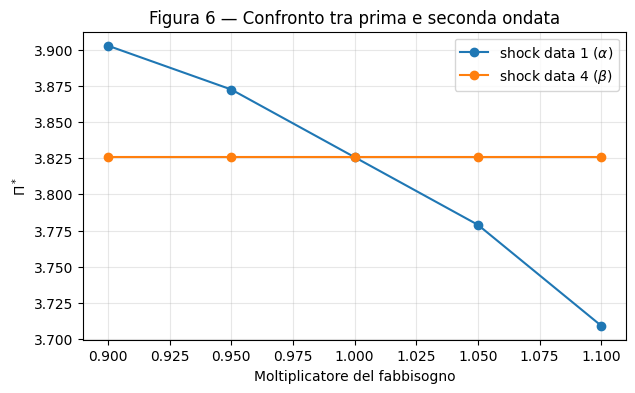

In [12]:
common = sorted(set(valid_alpha["alpha"]).intersection(set(valid_beta["beta"])))
cmp_rows = []
for q in common:
    ra = valid_alpha[np.isclose(valid_alpha["alpha"], q)].iloc[0]
    rb = valid_beta[np.isclose(valid_beta["beta"], q)].iloc[0]
    cmp_rows.append({
        "moltiplicatore": q,
        "Pi_alpha": ra["Pi"],
        "Pi_beta": rb["Pi"],
        "differenza_alpha_meno_beta": ra["Pi"] - rb["Pi"],
        "u1_alpha": ra["u1"],
        "u1_beta": rb["u1"],
        "legacy_slack_alpha": ra["legacy_slack"],
        "legacy_slack_beta": rb["legacy_slack"]
    })

df_compare = pd.DataFrame(cmp_rows)
display(df_compare)

plt.figure(figsize=(7, 4))
plt.plot(df_compare["moltiplicatore"], df_compare["Pi_alpha"], marker="o", label=r"shock data 1 ($\alpha$)")
plt.plot(df_compare["moltiplicatore"], df_compare["Pi_beta"], marker="o", label=r"shock data 4 ($\beta$)")
plt.xlabel("Moltiplicatore del fabbisogno")
plt.ylabel(r"$\Pi^*$")
plt.title("Figura 6 — Confronto tra prima e seconda ondata")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Tappa 9 — Sensitività rispetto a $\phi$  
**Regime B**

Si varia soltanto la capacità massima di funding:

$$
\phi\in\{0.30,0.40,\ldots,1.30\},
$$

mantenendo $\alpha=\beta=1$.

Il costo del funding non cambia. Per ogni data si calcola:

$$
\rho_t^u(\phi)=\frac{u_t^*(\phi)}{\phi\bar u_t}.
$$

,phi,success,status,Pi,Delta_Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_slack,prud_slack,x5_slack
0,0.3,True,0,3.810154,-0.015544,0.0,37.583333,0.0,35.0,27.416667,0.0,2.786733,7.525667,4.037488,1.200000,1.000000,0.0,0.0,0.0,0.0,0.0,0.14625,7.583333
1,0.4,True,0,3.817594,-0.008104,0.0,36.916667,0.0,35.0,28.083333,0.0,2.312867,7.249431,4.026261,1.600000,1.000000,0.0,0.0,0.0,0.0,0.0,0.07625,6.916667
2,0.5,True,0,3.825034,-0.000664,0.0,36.250000,0.0,35.0,28.750000,0.0,1.839000,6.973195,4.015034,2.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.00625,6.250000
3,0.6,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.848214,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
4,0.7,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.727041,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
5,0.8,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.636161,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
6,0.9,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.565476,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
7,1.0,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
8,1.1,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.462662,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476
9,1.2,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.424107,0.0,0.0,0.0,0.0,0.0,0.00000,6.190476


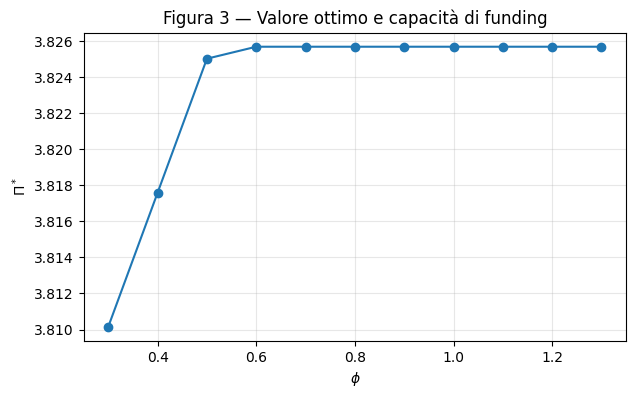

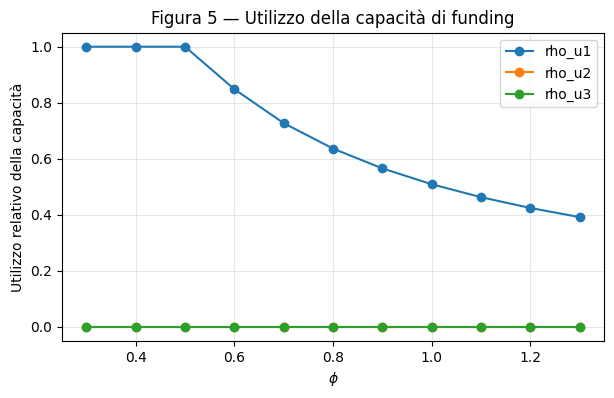

In [13]:
phi_grid = np.round(np.arange(0.30, 1.31, 0.10), 2)

df_phi = sensitivity_dataframe("phi", phi_grid)
display(df_phi)

valid_phi = df_phi[df_phi["success"]].copy()

plt.figure(figsize=(7, 4))
plt.plot(valid_phi["phi"], valid_phi["Pi"], marker="o")
plt.xlabel(r"$\phi$")
plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 3 — Valore ottimo e capacità di funding")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
for col in ["rho_u1", "rho_u2", "rho_u3"]:
    plt.plot(valid_phi["phi"], valid_phi[col], marker="o", label=col)
plt.xlabel(r"$\phi$")
plt.ylabel("Utilizzo relativo della capacità")
plt.title("Figura 5 — Utilizzo della capacità di funding")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Tappa 10 — Confronto delle sensitività  
**Regime A**

Questa tappa mette in relazione i tre driver senza trasformare il confronto in scenario analysis.

- $\alpha$: pressione alla prima data;
- $\beta$: pressione alla quarta data;
- $\phi$: disponibilità di capacità esterna.

La lettura deve collegare le variazioni di $\Pi^*$ e della soluzione agli eventuali cambiamenti del vincolo legacy, del limite su $x_5$ e dei bounds del funding.

In [14]:
summary_sens = pd.DataFrame([
    {
        "driver": "alpha",
        "min_param": df_alpha["alpha"].min(),
        "max_param": df_alpha["alpha"].max(),
        "n_fattibili": int(df_alpha["success"].sum()),
        "Pi_min_fattibile": df_alpha.loc[df_alpha["success"], "Pi"].min(),
        "Pi_max_fattibile": df_alpha.loc[df_alpha["success"], "Pi"].max()
    },
    {
        "driver": "beta",
        "min_param": df_beta["beta"].min(),
        "max_param": df_beta["beta"].max(),
        "n_fattibili": int(df_beta["success"].sum()),
        "Pi_min_fattibile": df_beta.loc[df_beta["success"], "Pi"].min(),
        "Pi_max_fattibile": df_beta.loc[df_beta["success"], "Pi"].max()
    },
    {
        "driver": "phi",
        "min_param": df_phi["phi"].min(),
        "max_param": df_phi["phi"].max(),
        "n_fattibili": int(df_phi["success"].sum()),
        "Pi_min_fattibile": df_phi.loc[df_phi["success"], "Pi"].min(),
        "Pi_max_fattibile": df_phi.loc[df_phi["success"], "Pi"].max()
    }
])
display(summary_sens)

,driver,min_param,max_param,n_fattibili,Pi_min_fattibile,Pi_max_fattibile
0,alpha,0.9,1.15,5,3.709183,3.902750
1,beta,0.9,1.15,5,3.825698,3.825698
2,phi,0.3,1.30,11,3.810154,3.825698


## Tappa 11 — Scenario analysis  
**Regime B**

Si risolvono esattamente le tre configurazioni assegnate:

| Scenario | $\alpha$ | $\beta$ | $\phi$ |
|---|---:|---:|---:|
| Standard | 1.00 | 1.00 | 1.00 |
| Mediamente critico | 1.03 | 1.03 | 0.90 |
| Critico | 1.06 | 1.06 | 0.75 |

Gli scenari sono deterministici e non hanno probabilità associate.

La perdita di valore è:

$$
L_s=\Pi_{\mathrm{Standard}}^*-\Pi_s^*.
$$

In [15]:
scenari = {
    "Standard": (1.00, 1.00, 1.00),
    "Mediamente critico": (1.03, 1.03, 0.90),
    "Critico": (1.06, 1.06, 0.75),
}

scenario_outputs = {}
rows = []

for nome, (a, b, p) in scenari.items():
    out = solve_model(a, b, p)
    scenario_outputs[nome] = out
    row = {"scenario": nome, "alpha": a, "beta": b, "phi": p, "success": out["success"]}
    if out["success"]:
        row["Pi"] = out["Pi"]
        for j in range(5):
            row[f"x{j+1}"] = out["x"][j]
        for t in range(4):
            row[f"g{t+1}"] = out["g"][t]
        for t in range(3):
            row[f"u{t+1}"] = out["u"][t]
            row[f"rho_u{t+1}"] = out["u"][t] / (p * u_bar[t])
        row["legacy_slack"] = out["x"][2] + out["x"][3] - L_legacy
    rows.append(row)

df_scenari = pd.DataFrame(rows)
Pi_standard = df_scenari.loc[df_scenari["scenario"] == "Standard", "Pi"].iloc[0]
df_scenari["perdita_vs_standard"] = np.where(
    df_scenari["success"],
    Pi_standard - df_scenari["Pi"],
    np.nan
)

display(df_scenari)

assert bool(df_scenari.loc[df_scenari["scenario"] == "Standard", "success"].iloc[0])
assert np.isclose(Pi_standard, Pi_bench)
print("Scenario Standard = benchmark: OK")

,scenario,alpha,beta,phi,success,Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_slack,perdita_vs_standard
0,Standard,1.00,1.00,1.00,True,3.825698,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,0.0,0.000000
1,Mediamente critico,1.03,1.03,0.90,True,3.797639,0.0,36.190476,0.0,35.0,28.809524,0.0,0.819410,5.966365,2.065972,2.995714,0.832143,0.0,0.0,0.0,0.0,0.0,0.028059
2,Critico,1.06,1.06,0.75,True,3.751804,0.0,37.783333,0.0,35.0,27.216667,0.0,0.974333,5.644205,0.144737,3.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.073895


Scenario Standard = benchmark: OK


## Tappa 12 — Controlli conclusivi  
**Regime A**

Prima dell'interpretazione finale si verifica congiuntamente:

1. corretta formulazione solver;
2. validità del benchmark;
3. corretta gestione del legacy e del relativo marginale;
4. riproduzione del benchmark mediante la funzione parametrica;
5. azione separata di $\alpha$, $\beta$ e $\phi$;
6. sviluppo separato delle due ondate prima del confronto;
7. uso esclusivo di risultati solver validi;
8. esatta parametrizzazione degli scenari;
9. rigenerabilità di tabelle e grafici;
10. assenza di valori ottimi inseriti manualmente nelle celle successive.

In [16]:
checks = {
    "benchmark_success": res_bench.success,
    "eq_residuals_ok": np.max(np.abs(eq_resid)) <= 1e-7,
    "inequalities_ok": np.all(ub_slack >= -1e-7),
    "nonnegative_ok": np.min(z_bench) >= -1e-7,
    "legacy_marginal_ok": abs(derivata_numerica - m_legacy) < 1e-6,
    "parametric_benchmark_ok": np.allclose(bench_fun["z"], z_bench, atol=1e-8),
    "alpha_grid_complete": len(df_alpha) == 6,
    "beta_grid_complete": len(df_beta) == 6,
    "phi_grid_complete": len(df_phi) == 11,
    "scenarios_complete": len(df_scenari) == 3,
    "standard_equals_benchmark": np.isclose(Pi_standard, Pi_bench),
}

check_df = pd.DataFrame({"controllo": list(checks.keys()), "esito": list(checks.values())})
display(check_df)

if not all(checks.values()):
    raise AssertionError("Almeno un controllo conclusivo non è soddisfatto.")

print("Tutti i controlli conclusivi previsti in questa implementazione sono soddisfatti.")

,controllo,esito
0,benchmark_success,True
1,eq_residuals_ok,True
2,inequalities_ok,True
3,nonnegative_ok,True
4,legacy_marginal_ok,True
5,parametric_benchmark_ok,True
6,alpha_grid_complete,True
7,beta_grid_complete,True
8,phi_grid_complete,True
9,scenarios_complete,True


Tutti i controlli conclusivi previsti in questa implementazione sono soddisfatti.


# Elementi quantitativi per l'interpretazione finale

Il notebook ha prodotto e validato gli elementi necessari per discutere:

- la composizione ottima del benchmark;
- il ruolo dei bilanci temporali;
- il ruolo e il marginale locale del vincolo legacy;
- la diversa risposta a shock della stessa intensità relativa alla data 1 e alla data 4;
- il valore operativo della capacità di funding;
- i cambiamenti di fattibilità e dei vincoli attivi lungo le griglie;
- il confronto tra Standard, Mediamente critico e Critico.

L'interpretazione deve restare entro i limiti del modello: i coefficienti sono didattici e stilizzati, gli scenari sono deterministici, non sono modellati fire sales, feedback di mercato, dinamica endogena dei depositi o decisioni adattive.

## Traccia per il commento finale dello studente

Il commento finale dovrebbe discutere autonomamente:

1. ruolo del timing dei fabbisogni;
2. ruolo della rigidità legacy;
3. ruolo del limite su $x_5$ quando rilevante;
4. ruolo della capacità di funding;
5. differenza tra sensitività univariata e scenario analysis;
6. limiti del modello;
7. distinzione tra risultati del modello stilizzato e fatti storici relativi a First Republic Bank.

Questa cella non sostituisce l'interpretazione finanziaria autonoma dello studente.